In [ ]:
!pip install ultralytics opencv-python matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.3/45.3 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.2 MB/s eta 0:00:00


In [4]:
# ==========================================================
# Install Required Libraries
# ==========================================================
!pip install -q ultralytics roboflow matplotlib opencv-python

# ==========================================================
# Import Libraries
# ==========================================================
from roboflow import Roboflow
from ultralytics import YOLO
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
import random
import glob
import os
import shutil

# ==========================================================
# Configuration
# ==========================================================
MODEL_WEIGHTS = "yolov8n.pt"
EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 16


In [5]:
# ==========================================================
# Download Dataset from Roboflow
# ==========================================================
rf = Roboflow(api_key="ozfVZSnly9eFHEaYAxXb")

project = rf.workspace("tanvirtain").project("bangladeshi-currency-detection")

dataset = project.version(3).download("yolov8")

DATASET_PATH = dataset.location

print(f"Dataset downloaded to:\n{DATASET_PATH}")

loading Roboflow workspace...
loading Roboflow project...
Dataset downloaded to:
/content/Bangladeshi-Currency-Detection-3


In [6]:
# ==========================================================
# Read Class Names
# ==========================================================
import yaml

yaml_path = os.path.join(DATASET_PATH, "data.yaml")

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

CLASS_NAMES = data["names"]

print("\nClasses:")
print(CLASS_NAMES)


Classes:
['500 taka', 'Fifty taka', 'Five Hundred taka', 'Five Taka', 'One Taka', 'One Thousand taka', 'Ten Taka', 'Twenty', 'currency', 'one hundred taka', 'two taka']



Total Training Images : 1166


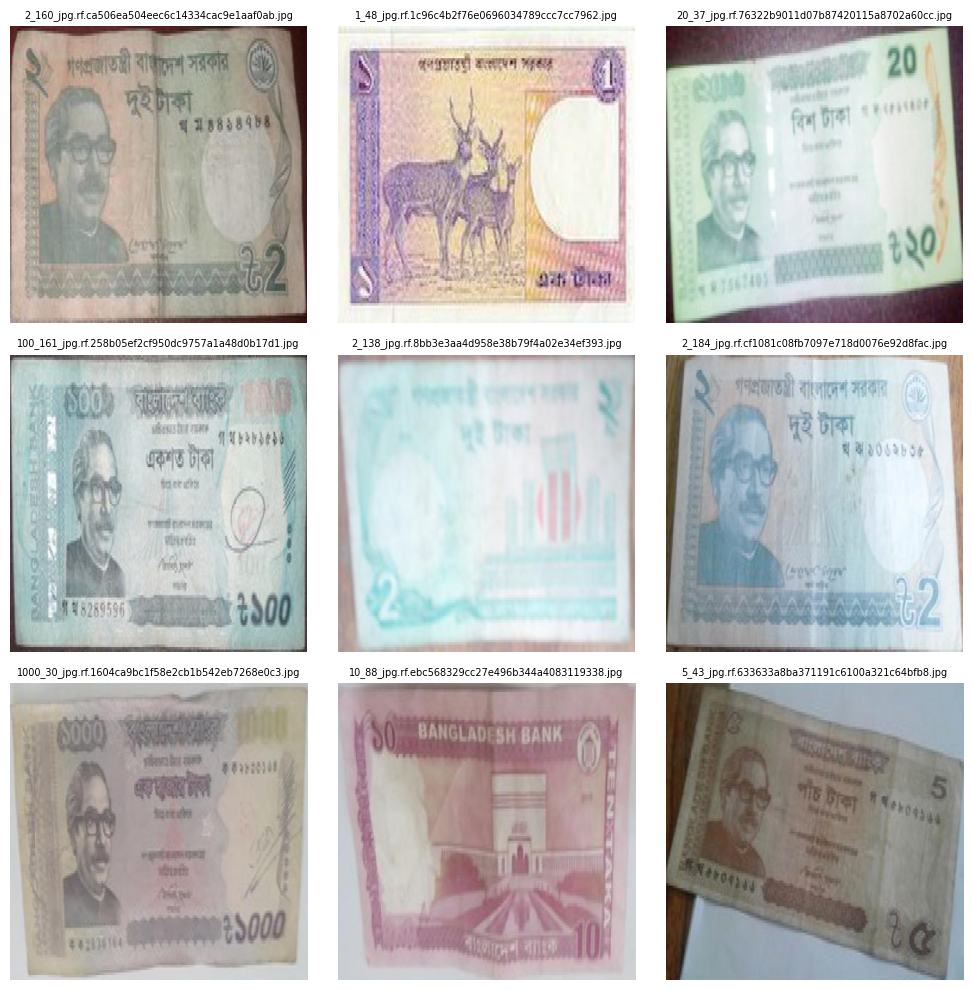

In [7]:
# ==========================================================
# Preview Dataset Images
# ==========================================================
train_images = glob.glob(os.path.join(DATASET_PATH, "train/images/*.jpg"))
train_images += glob.glob(os.path.join(DATASET_PATH, "train/images/*.png"))
train_images += glob.glob(os.path.join(DATASET_PATH, "train/images/*.jpeg"))

print(f"\nTotal Training Images : {len(train_images)}")

sample = random.sample(train_images, min(9, len(train_images)))

fig, axes = plt.subplots(3,3, figsize=(10,10))

for ax, img_path in zip(axes.flatten(), sample):
    img = mpimg.imread(img_path)
    ax.imshow(img)
    ax.set_title(os.path.basename(img_path), fontsize=7)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [8]:
# ==========================================================
# Load Pretrained YOLOv8
# ==========================================================
model = YOLO(MODEL_WEIGHTS)

print(f"\nLoaded {MODEL_WEIGHTS}")


Loaded yolov8n.pt


In [9]:
# ==========================================================
# Train Model
# ==========================================================
results = model.train(
    data=yaml_path,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    project="runs",
    name="bangladesh_banknote",
    exist_ok=True,
    patience=10,
    save=True,
    plots=True,
    verbose=False
)

print("\nTraining Finished!")

Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bangladeshi-Currency-Detection-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=bangladesh_banknote, nbs=64, nm

In [13]:
# ==========================================================
# Best Model Path
# ==========================================================
best_model_path = "/content/runs/detect/runs/bangladesh_banknote/weights/best.pt"

print(best_model_path)

# ==========================================================
# Load Models
# ==========================================================
base_model = YOLO(MODEL_WEIGHTS)
finetuned_model = YOLO(best_model_path)

# ==========================================================
# Test Images
# ==========================================================
test_images = glob.glob(os.path.join(DATASET_PATH, "test/images/*.jpg"))
test_images += glob.glob(os.path.join(DATASET_PATH, "test/images/*.png"))
test_images += glob.glob(os.path.join(DATASET_PATH, "test/images/*.jpeg"))

sample_test = random.sample(test_images, min(2, len(test_images)))


/content/runs/detect/runs/bangladesh_banknote/weights/best.pt


In [12]:
import os

for root, dirs, files in os.walk("/content/runs"):
    for file in files:
        if file == "best.pt":
            print(os.path.join(root, file))

/content/runs/detect/runs/bangladesh_banknote/weights/best.pt


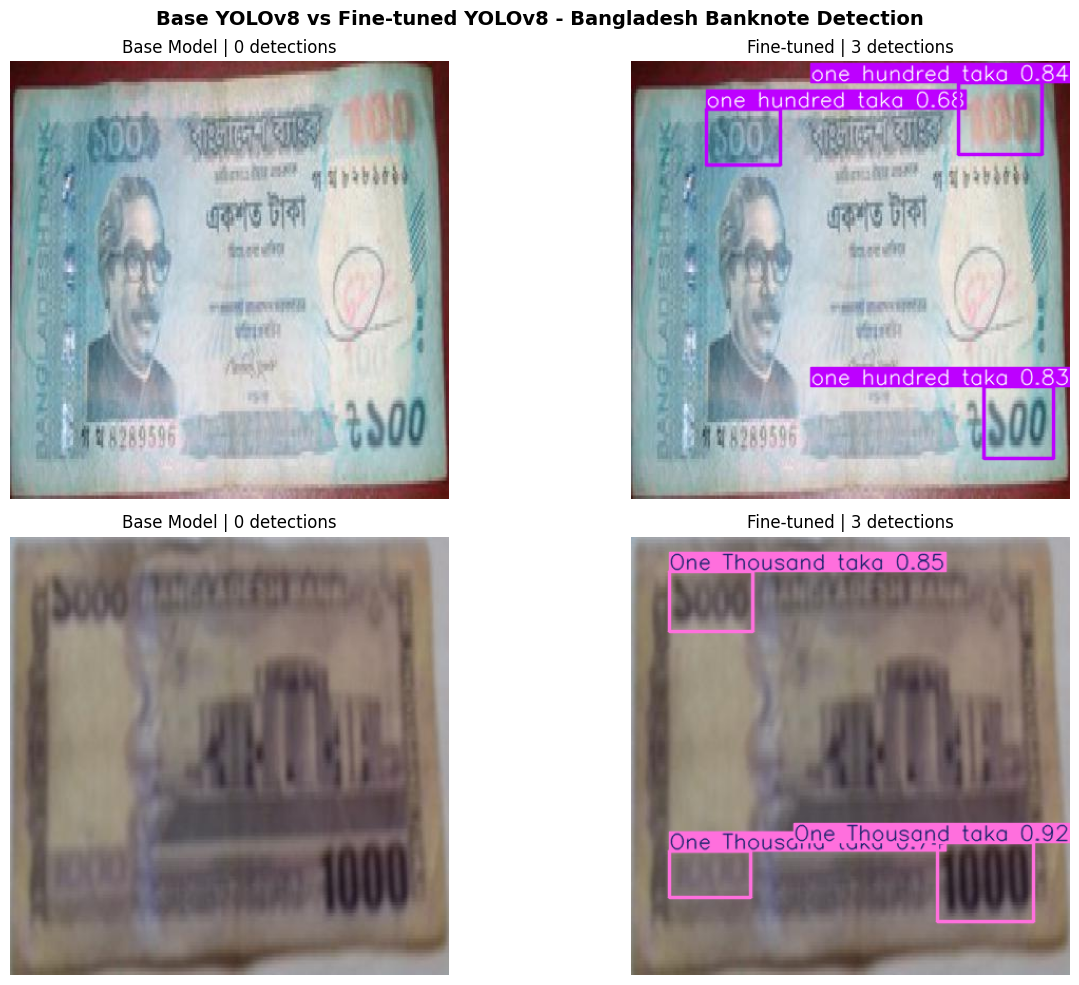

In [14]:
# ==========================================================
# Compare Base vs Fine-tuned
# ==========================================================
fig, axes = plt.subplots(2,2, figsize=(14,10))

fig.suptitle(
    "Base YOLOv8 vs Fine-tuned YOLOv8 - Bangladesh Banknote Detection",
    fontsize=14,
    fontweight="bold"
)

for row, img_path in enumerate(sample_test):

    # Base Model
    base_result = base_model.predict(
        img_path,
        conf=0.25,
        verbose=False
    )

    base_img = cv2.cvtColor(
        base_result[0].plot(),
        cv2.COLOR_BGR2RGB
    )

    base_det = len(base_result[0].boxes)

    # Fine-tuned Model
    tuned_result = finetuned_model.predict(
        img_path,
        conf=0.25,
        verbose=False
    )

    tuned_img = cv2.cvtColor(
        tuned_result[0].plot(),
        cv2.COLOR_BGR2RGB
    )

    tuned_det = len(tuned_result[0].boxes)

    axes[row,0].imshow(base_img)
    axes[row,0].set_title(f"Base Model | {base_det} detections")
    axes[row,0].axis("off")

    axes[row,1].imshow(tuned_img)
    axes[row,1].set_title(f"Fine-tuned | {tuned_det} detections")
    axes[row,1].axis("off")

    axes[row,0].set_ylabel(
        os.path.basename(img_path),
        rotation=90,
        fontsize=8
    )

plt.tight_layout()
plt.show()


In [15]:
# ==========================================================
# Validation Metrics
# ==========================================================
metrics = finetuned_model.val()

print("\nValidation Metrics")
print(metrics)

Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 547.6±141.0 MB/s, size: 16.8 KB)
val: Scanning /content/Bangladeshi-Currency-Detection-3/valid/labels.cache... 168 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 168/168 41.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 3.0it/s 3.7s
                   all        168        433      0.923      0.929       0.95      0.567
              500 taka         38         68      0.804      0.765      0.882      0.384
            Fifty taka         18         39      0.929      0.897      0.899      0.379
             Five Taka         19         60      0.948      0.916       0.95      0.499
              One Taka          9         26      0.918      0.962      0.965      0.705
     One Thousand taka         14         36       0.86      0.972      0.962      0.681
              T

In [16]:
# ==========================================================
# Save Best Model
# ==========================================================
SAVE_DIR = "/content/bangladesh_banknote_model"

os.makedirs(SAVE_DIR, exist_ok=True)

shutil.copy(best_model_path, SAVE_DIR + "/best.pt")

print("\nSaved model to:")
print(SAVE_DIR + "/best.pt")



Saved model to:
/content/bangladesh_banknote_model/best.pt


In [17]:
# ==========================================================
# Predict on a Single Image
# ==========================================================
image_path = random.choice(test_images)

results = finetuned_model.predict(
    image_path,
    conf=0.25,
    save=True
)

print("\nPrediction completed.")

Results saved to /content/runs/detect/predict

Prediction completed.
